In [52]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow version:", tf.__version__)

DATASET_DIR = "D:\\COMPUTER VISION\\lab2\\Rice_Image_Dataset"

print(os.listdir(DATASET_DIR))

TensorFlow version: 2.21.0
['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']


In [53]:
classes = sorted(os.listdir(DATASET_DIR))
print("Classes found:", classes)

for c in classes:
    class_path = os.path.join(DATASET_DIR, c)
    n_images = len(os.listdir(class_path))
    print(f"{c}: {n_images} images")

Classes found: ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']
Arborio: 15000 images
Basmati: 15000 images
Ipsala: 15000 images
Jasmine: 15000 images
Karacadag: 15000 images


Smallest class: Arborio (15000 images)
Largest class: Arborio (15000 images)



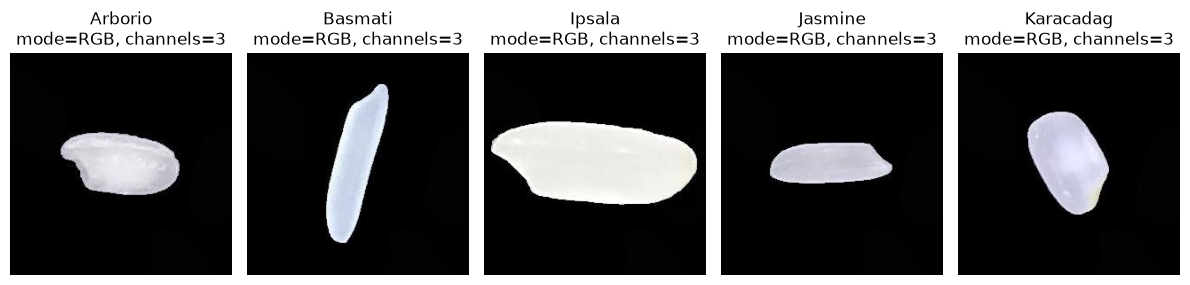

In [23]:
from PIL import Image

class_counts = {}
for c in classes:
    class_path = os.path.join(DATASET_DIR, c)
    class_counts[c] = len(os.listdir(class_path))

smallest_class = min(class_counts, key=class_counts.get)
largest_class = max(class_counts, key=class_counts.get)

print(f"Smallest class: {smallest_class} ({class_counts[smallest_class]} images)")
print(f"Largest class: {largest_class} ({class_counts[largest_class]} images)")
print()

plt.figure(figsize=(12, 6))
for i, c in enumerate(classes):
    class_path = os.path.join(DATASET_DIR, c)
    sample_img_name = os.listdir(class_path)[0]
    img_path = os.path.join(class_path, sample_img_name)

    with Image.open(img_path) as img:
        mode = img.mode
        channels = len(img.getbands())  # e.g. RGB -> 3, L -> 1, RGBA -> 4
        img_display = img.copy()

    plt.subplot(1, len(classes), i + 1)
    plt.imshow(img_display)
    plt.title(f"{c}\nmode={mode}, channels={channels}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [39]:
IMG_SIZE = (32, 32)
BATCH_SIZE = 8
SEED = 123

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.3,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.3,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 75000 files belonging to 5 classes.
Using 52500 files for training.
Found 75000 files belonging to 5 classes.
Using 22500 files for validation.
Classes: ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']


In [25]:
val_batches = tf.data.experimental.cardinality(val_test_ds)
test_ds = val_test_ds.take(val_batches // 2)
val_ds = val_test_ds.skip(val_batches // 2)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Train batches: 6563
Val batches: 1407
Test batches: 1406


In [40]:
normalization_layer = layers.Rescaling(1./255)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(buffer_size=AUTOTUNE)

In [41]:
num_classes = len(class_names)

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 820,229 (3.13 MB)

 Trainable params: 820,229 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

In [43]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [32]:
EPOCHS = 3

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/3


C:\Users\Jasmin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


6563/6563 ━━━━━━━━━━━━━━━━━━━━ 1785s 272ms/step - accuracy: 0.9457 - loss: 0.1611 - val_accuracy: 0.9708 - val_loss: 0.0838
Epoch 2/3
6563/6563 ━━━━━━━━━━━━━━━━━━━━ 21193s 3s/step - accuracy: 0.9701 - loss: 0.0861 - val_accuracy: 0.9735 - val_loss: 0.0733
Epoch 3/3
6563/6563 ━━━━━━━━━━━━━━━━━━━━ 184s 28ms/step - accuracy: 0.9739 - loss: 0.0774 - val_accuracy: 0.9764 - val_loss: 0.0674


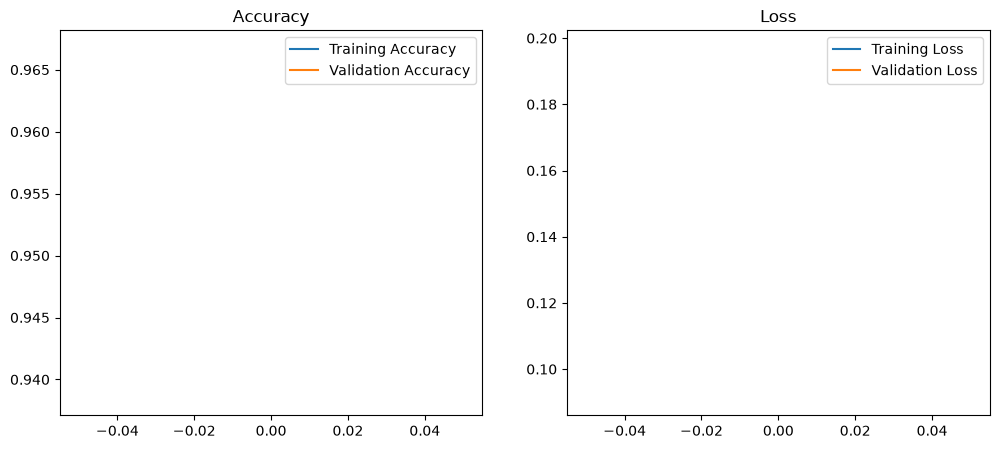

In [13]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(EPOCHS)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss')
plt.show()

In [54]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc:.4f}")

352/352 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.9562 - loss: 0.1227
Test Accuracy: 0.9562


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 395ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 434ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0

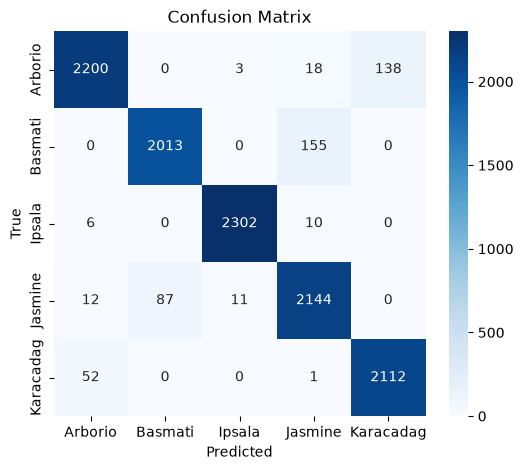

In [55]:
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [56]:
resolutions = ['32x32', '64x64', '128x128']

test_accuracies = [0.9752, 0.9691, 0.9668]
training_times_min = [38 + 49/60, 24 + 46.7/60, 47 + 16.8/60]  # = [38.82, 24.78, 47.28]

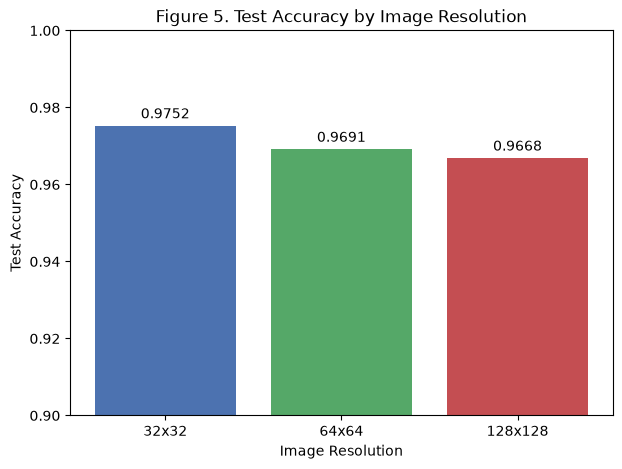

In [57]:
plt.figure(figsize=(7, 5))
plt.bar(resolutions, test_accuracies, color=['#4C72B0', '#55A868', '#C44E52'])
plt.ylabel("Test Accuracy")
plt.xlabel("Image Resolution")
plt.title("Figure 5. Test Accuracy by Image Resolution")
plt.ylim(0.90, 1.0)

for i, acc in enumerate(test_accuracies):
    plt.text(i, acc + 0.002, f"{acc:.4f}", ha='center')

plt.show()

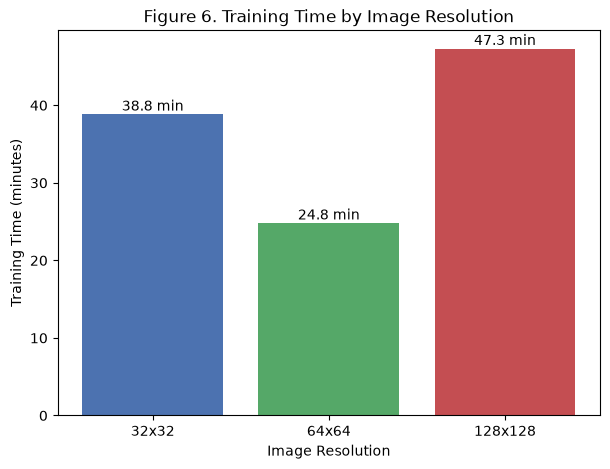

In [58]:
plt.figure(figsize=(7, 5))
plt.bar(resolutions, training_times_min, color=['#4C72B0', '#55A868', '#C44E52'])
plt.ylabel("Training Time (minutes)")
plt.xlabel("Image Resolution")
plt.title("Figure 6. Training Time by Image Resolution")

for i, t in enumerate(training_times_min):
    plt.text(i, t + 0.5, f"{t:.1f} min", ha='center')

plt.show()

In [59]:
IMG_SIZE = (32, 32)
BATCH_SIZE = 32
SEED = 123

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR, validation_split=0.3, subset="training",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE
)
val_test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR, validation_split=0.3, subset="validation",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

val_batches = tf.data.experimental.cardinality(val_test_ds)
test_ds = val_test_ds.take(val_batches // 2)
val_ds = val_test_ds.skip(val_batches // 2)

normalization_layer = layers.Rescaling(1./255)
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(buffer_size=AUTOTUNE)

print("Data reloaded and normalized ONCE. Do not rerun this cell again without restarting the kernel.")

Found 75000 files belonging to 5 classes.
Using 52500 files for training.
Found 75000 files belonging to 5 classes.
Using 22500 files for validation.
Data reloaded and normalized ONCE. Do not rerun this cell again without restarting the kernel.


In [60]:
num_classes = len(class_names)

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS = 3
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)

Epoch 1/3


C:\Users\Jasmin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1641/1641 ━━━━━━━━━━━━━━━━━━━━ 1580s 962ms/step - accuracy: 0.9502 - loss: 0.1405 - val_accuracy: 0.9656 - val_loss: 0.1048
Epoch 2/3
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.9688 - loss: 0.0878 - val_accuracy: 0.9721 - val_loss: 0.0829
Epoch 3/3
1641/1641 ━━━━━━━━━━━━━━━━━━━━ 28s 17ms/step - accuracy: 0.9748 - loss: 0.0720 - val_accuracy: 0.9757 - val_loss: 0.0772


In [61]:
# Collect images, true labels, and predicted labels together
all_images = []
all_true = []
all_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    pred_labels = np.argmax(preds, axis=1)
    all_images.extend(images.numpy())
    all_true.extend(labels.numpy())
    all_pred.extend(pred_labels)

all_images = np.array(all_images)
all_true = np.array(all_true)
all_pred = np.array(all_pred)

correct_idx = np.where(all_true == all_pred)[0]
incorrect_idx = np.where(all_true != all_pred)[0]

print(f"Correct predictions: {len(correct_idx)}")
print(f"Incorrect predictions: {len(incorrect_idx)}")

Correct predictions: 10968
Incorrect predictions: 296


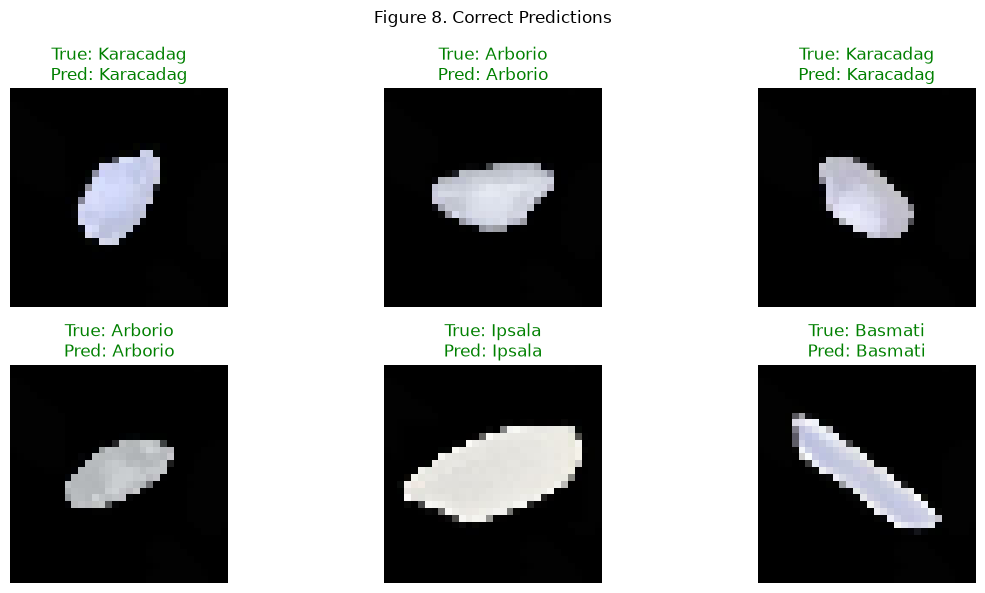

In [62]:
plt.figure(figsize=(12, 6))
sample_correct = np.random.choice(correct_idx, 6, replace=False)

for i, idx in enumerate(sample_correct):
    plt.subplot(2, 3, i + 1)
    plt.imshow(all_images[idx])
    plt.title(f"True: {class_names[all_true[idx]]}\nPred: {class_names[all_pred[idx]]}", color='green')
    plt.axis('off')

plt.suptitle("Figure 8. Correct Predictions")
plt.tight_layout()
plt.show()

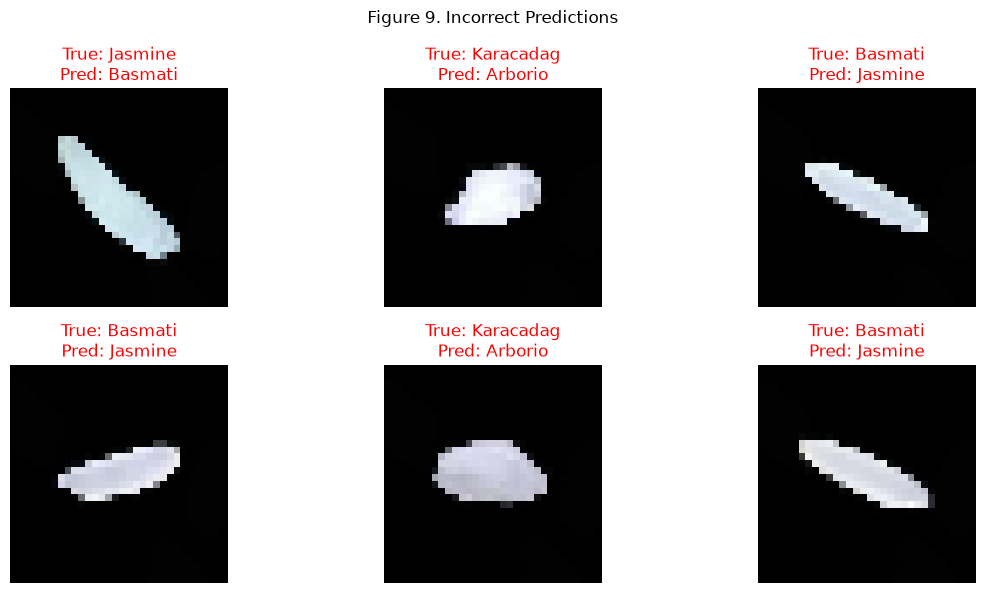

In [63]:
plt.figure(figsize=(12, 6))
n_show = min(6, len(incorrect_idx))
sample_incorrect = np.random.choice(incorrect_idx, n_show, replace=False)

for i, idx in enumerate(sample_incorrect):
    plt.subplot(2, 3, i + 1)
    plt.imshow(all_images[idx])
    plt.title(f"True: {class_names[all_true[idx]]}\nPred: {class_names[all_pred[idx]]}", color='red')
    plt.axis('off')

plt.suptitle("Figure 9. Incorrect Predictions")
plt.tight_layout()
plt.show()

In [66]:
for i, idx in enumerate(sample_incorrect[:5]):
    print(f"Image {i+1}: Actual = {class_names[all_true[idx]]}, Predicted = {class_names[all_pred[idx]]}")

Image 1: Actual = Jasmine, Predicted = Basmati
Image 2: Actual = Karacadag, Predicted = Arborio
Image 3: Actual = Basmati, Predicted = Jasmine
Image 4: Actual = Basmati, Predicted = Jasmine
Image 5: Actual = Karacadag, Predicted = Arborio


In [65]:
print("Min pixel value:", all_images.min())
print("Max pixel value:", all_images.max())
print("Sample pixel values:", all_images[0][0][0])

Min pixel value: 0.0
Max pixel value: 1.0
Sample pixel values: [0. 0. 0.]
